In [1]:
# !pip install ultralytics opencv-python-headless matplotlib scipy torch torchvision tqdm einops
# !pip install kagglehub
# pip install ultralytics torch torchvision opencv-python matplotlib scipy tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 20.1 MB/s eta 0:00:00


In [1]:
# !pip install gradio
# !pip install ffmpeg-python
# !pip install moviepy==1.0.3

   ---------------------------------------- 0.0/42.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/42.9 MB ? eta -:--:--
   -- ------------------------------------- 2.4/42.9 MB 6.7 MB/s eta 0:00:07
   ---- ----------------------------------- 5.0/42.9 MB 9.1 MB/s eta 0:00:05
   ------- -------------------------------- 7.6/42.9 MB 10.2 MB/s eta 0:00:04
   --------- ------------------------------ 10.0/42.9 MB 10.7 MB/s eta 0:00:04
   ----------- ---------------------------- 12.8/42.9 MB 11.0 MB/s eta 0:00:03
   -------------- ------------------------- 15.5/42.9 MB 11.4 MB/s eta 0:00:03
   ---------------- ----------------------- 18.1/42.9 MB 11.5 MB/s eta 0:00:03
   ------------------- -------------------- 20.7/42.9 MB 11.7 MB/s eta 0:00:02
   --------------------- ------------------ 23.1/42.9 MB 11.8 MB/s eta 0:00:02
   ----------------------- ---------------- 25.7/42.9 MB 11.8 MB/s eta 0:00:02
   -------------------------- ------------- 28.3/42.9 MB 11.8 MB/s eta 0:00


[notice] A new release of pip is available: 24.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import os
import glob
import math
import random
import time
import time
import json
from pathlib import Path


import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader

from ultralytics import YOLO
# 1 this
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [8]:
# import kagglehub
# path = kagglehub.dataset_download("kaushalbora18/penn-action-dataset")
# print("Downloaded to:", path)

100%|██████████| 3.21G/3.21G [00:43<00:00, 78.4MB/s]

Extracting files...


Downloaded to: /root/.cache/kagglehub/datasets/kaushalbora18/penn-action-dataset/versions/1


In [9]:
# for f in os.listdir(os.path.join(path, "Penn_Action")):
#     print(f)
#
# PENNACTION_ROOT = os.path.join(path, "Penn_Action")
# FRAMES_DIR = os.path.join(PENNACTION_ROOT, "frames")
# LABELS_DIR = os.path.join(PENNACTION_ROOT, "labels")
# PRECOMP_DIR = "precomputed_rep_penn"
# os.makedirs(PRECOMP_DIR, exist_ok=True)
# print("Precomputed saved to:", os.path.abspath(PRECOMP_DIR))
#
# print("Example frame folders:", sorted(os.listdir(FRAMES_DIR))[:10])
# print("Example label files:", sorted(os.listdir(LABELS_DIR))[:10])

frames
tools
README
labels
Precomputed saved to: /content/precomputed_rep_penn
Example frame folders: ['0001', '0002', '0003', '0004', '0005', '0006', '0007', '0008', '0009', '0010']
Example label files: ['0001.mat', '0002.mat', '0003.mat', '0004.mat', '0005.mat', '0006.mat', '0007.mat', '0008.mat', '0009.mat', '0010.mat']


In [2]:
# 2 this
PROJECT_ROOT = os.getcwd()

DATA_DIR = os.path.join(PROJECT_ROOT, "data")
PENNACTION_DIR = os.path.join(DATA_DIR, "Penn_Action/Penn_Action")
for f in os.listdir(PENNACTION_DIR):
    print(f)
FRAMES_DIR = os.path.join(PENNACTION_DIR, "frames")
LABELS_DIR = os.path.join(PENNACTION_DIR, "labels")
VIDEO_SOURCE_DIR = os.path.join(DATA_DIR, "RepPenn_Videos/RepPenn_Videos")
WEB_VIDEO_SOURCE_DIR = os.path.join(DATA_DIR, "RepPenn_Videos/Web_Safe_Videos")

NPZ_OUTPUT_DIR = os.path.join(DATA_DIR, "RepPenn_Features")
os.makedirs(NPZ_OUTPUT_DIR, exist_ok=True)

frames
labels
README
tools


Found sequences: 2326
First 10 sequences: ['0001', '0002', '0003', '0004', '0005', '0006', '0007', '0008', '0009', '0010']
Annotation keys: dict_keys(['__header__', '__version__', '__globals__', 'action', 'pose', 'x', 'y', 'visibility', 'train', 'bbox', 'dimensions', 'nframes'])
action : baseball_pitch
pose : back
x : [[      136.5         135      102.75 ...         102      141.75          93]
 [     131.25      134.25      102.75 ...         102       139.5          93]
 [      130.5      134.25      102.75 ...         102      137.25          93]
 ...
 [        165       93.75      159.75 ...       196.5      293.25       181.5]
 [        165          90      159.75 ...       196.5      294.75      180.75]
 [     164.25       87.75       160.5 ...      197.25         297      180.75]]
y : [[      71.25      102.75          99 ...      255.75      324.75         321]
 [      66.75         102       98.25 ...         255         324      320.25]
 [      66.75         102       98.25 

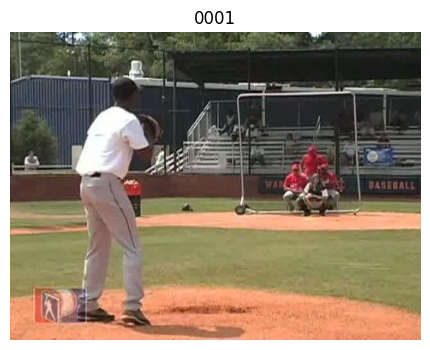

In [3]:
# this
def list_sequences(frames_dir=FRAMES_DIR):
    seqs = sorted([d for d in os.listdir(frames_dir) if os.path.isdir(os.path.join(frames_dir, d))])
    return seqs

seqs = list_sequences()
print("Found sequences:", len(seqs))
print("First 10 sequences:", seqs[:10])

def preview_sequence(seq_id):
    seq_dir = os.path.join(FRAMES_DIR, seq_id)
    mat_path = os.path.join(LABELS_DIR, f"{seq_id}.mat")
    ann = loadmat(mat_path, squeeze_me=True, struct_as_record=False)
    print("Annotation keys:", ann.keys())
    try:
        for k in ['action','pose','x','y','visibility','nframes']:
            if k in ann:
                print(k, ":", ann[k])
    except Exception as e:
        print("Could not parse .mat with simple accessor — printing mat keys:", e)
    first_frame = os.path.join(seq_dir, sorted(os.listdir(seq_dir))[0])
    img = cv2.imread(first_frame)[:,:,::-1]
    plt.figure(figsize=(6,4))
    plt.imshow(img)
    plt.title(seq_id)
    plt.axis('off')

preview_sequence(seqs[0])

In [4]:
# 3 this
yolo_pose = YOLO("yolov8n-pose.pt")

def extract_kps_yolo(frames, batch_size=12):
    all_kps = []

    for i in range(0, len(frames), batch_size):
        batch = frames[i : i + batch_size]

        results = yolo_pose(batch, verbose=False)

        for r in results:
            if r.keypoints is not None and r.keypoints.data.shape[0] > 0:
                kps_tensor = r.keypoints.data[0]
                kps_np = kps_tensor.cpu().numpy()
            else:
                kps_np = np.zeros((17, 3), dtype=np.float32)
            all_kps.append(kps_np)
        del results

    return np.stack(all_kps, axis=0)

In [5]:
#4 this

def keypoints_to_heatmaps(kps, output_size=(64,64), sigma=1.5, selected_indices=None):
    F, K, _ = kps.shape
    H, W = output_size
    if selected_indices is None:
        selected_indices = list(range(K))
    Ksel = len(selected_indices)
    heatmaps = np.zeros((F, Ksel, H, W), dtype=np.float32)

    xs = np.arange(W)
    ys = np.arange(H)
    xv, yv = np.meshgrid(xs, ys)

    for f in range(F):
        for ki, kidx in enumerate(selected_indices):
            x, y, vis = kps[f, kidx]
            if vis < 0.1 or x<=0 or y<=0:
                continue
            cx = x
            cy = y
            g = np.exp(-((xv - cx)**2 + (yv - cy)**2) / (2 * sigma * sigma))
            heatmaps[f, ki] = g
        # heatmaps[f] /= (heatmaps[f].max(axis=(1,2), keepdims=True) + 1e-6)
    return heatmaps  # (F, Ksel, H, W)


In [6]:
#5 this
def scale_keypoints_to_size(kps, frame_size, target_size=(64,64)):
    Wf, Hf = frame_size
    Wt, Ht = target_size
    scale_x = Wt / float(Wf)
    scale_y = Ht / float(Hf)
    kps_scaled = kps.copy()
    kps_scaled[:, :, 0] = kps[:, :, 0] * scale_x
    kps_scaled[:, :, 1] = kps[:, :, 1] * scale_y
    return kps_scaled

def heatmaps_to_Pmap(heatmaps):
    F, K, H, W = heatmaps.shape
    J = heatmaps.transpose(2,3,0,1)  # (H,W,F,K)

    A = J.mean(0)   # (W,F,K)
    B = J.mean(1)   # (H,F,K)
    P = np.concatenate([B,A],axis=0)  # (H+W, F, K)

    Pn = 255*(P - P.min())/(P.max()-P.min()+1e-6)

    feat = np.zeros((224,224,K), np.uint8)
    for k in range(K):
        feat[:,:,k] = cv2.resize(Pn[:,:,k].astype(np.uint8), (224,224))

    return torch.from_numpy(feat.transpose(2,0,1)).float() / 255.0

def heatmaps_to_processed_feature(heatmaps):
    # (F, K, H, W) to J[h,w,f,k]
    J = np.transpose(heatmaps, (2,3,0,1))  # (H,W,F,K)
    A = np.mean(J, axis=0)  # (W, F, K)
    B = np.mean(J, axis=1)  # (H, F, K)
    P = np.concatenate([B, A], axis=0)  # (H+W, F, K)
    pmin, pmax = P.min(), P.max()
    if pmax - pmin < 1e-6:
        Pn = np.zeros_like(P)
    else:
        Pn = 255.0 * (P - pmin) / (pmax - pmin)
    Kfeat = Pn.shape[2]
    feat_maps = np.zeros((224,224,Kfeat), dtype=np.uint8)
    for k in range(Kfeat):
        mat = Pn[:,:,k]  # shape ((H+W), F)
        mat_norm = mat.astype(np.uint8)
        resized = cv2.resize(mat_norm, (224,224), interpolation=cv2.INTER_LINEAR)
        feat_maps[:,:,k] = resized
    return feat_maps

In [7]:
# 6 this
from scipy.io import loadmat
import glob

rep_penn_actions = ["bench_press", "clean_and_jerk", "jumping_jacks", "pullup",
                    "pushup", "situp", "squat"]
action_to_idx = {a:i for i,a in enumerate(rep_penn_actions)}

labels_map = {}

mat_files = sorted(glob.glob(os.path.join(LABELS_DIR, "*.mat")))

print(f"Found {len(mat_files)} annotation files.")

for mat_path in mat_files:
    sid = os.path.splitext(os.path.basename(mat_path))[0]

    try:
        ann = loadmat(mat_path, squeeze_me=True, struct_as_record=False)
        action_str = ann['action']

        if action_str in action_to_idx:
            labels_map[sid] = (action_str, action_to_idx[action_str])

    except Exception as e:
        print(f"Error reading {mat_path}: {e}")

print(f"Mapped {len(labels_map)} sequences to Rep-Penn classes.")

all_valid_ids = list(labels_map.keys())
random.shuffle(all_valid_ids)
split = int(0.8 * len(all_valid_ids))
train_seqs = set(all_valid_ids[:split])
test_seqs = set(all_valid_ids[split:])

Found 2326 annotation files.
Mapped 1081 sequences to Rep-Penn classes.


In [23]:
# import shutil
#
# if os.path.exists(PRECOMP_DIR):
#     shutil.rmtree(PRECOMP_DIR)
#     print(f"Successfully deleted {PRECOMP_DIR}")
# else:
#     print(f"{PRECOMP_DIR} does not exist (nothing to delete).")

Successfully deleted precomputed_rep_penn


In [6]:
# from google.colab import drive
# import os
#
# drive.mount('/content/drive')
#
# VIDEO_SAVE_DIR = '/content/drive/MyDrive/RepPenn_Videos'
# os.makedirs(VIDEO_SAVE_DIR, exist_ok=True)

Mounted at /content/drive


In [29]:
# import cv2
# import glob
# from tqdm import tqdm
# import numpy as np
#
# cycles_choices = [6, 8, 10]
# speeds_choices = [1, 2]
# resize_dim = (640, 480)
#
# def create_video_from_frames(output_path, frames, fps=30):
#     if not frames: return
#
#     height, width, layers = frames[0].shape
#     fourcc = cv2.VideoWriter_fourcc(*'mp4v')
#     video = cv2.VideoWriter(output_path, fourcc, fps, (width, height))
#
#     for frame in frames:
#         video.write(frame)
#
#     video.release()
#
# print(f"Generating videos into: {VIDEO_SAVE_DIR}") # VIDEO_SOURCE_DIR
#
# all_seq_ids = train_seqs + test_seqs
#
# for sid in tqdm(all_seq_ids, desc="Generating Videos"):
#     seq_dir = os.path.join(FRAMES_DIR, sid)
#     frame_files = sorted(glob.glob(os.path.join(seq_dir, "*.jpg")))
#
#     if len(frame_files) == 0: continue
#
#     original_frames = []
#     for fp in frame_files:
#         img = cv2.imread(fp)
#         if img is not None:
#             img = cv2.resize(img, resize_dim)
#             original_frames.append(img)
#
#     if not original_frames: continue
#
#     P = original_frames
#     R = original_frames[::-1]
#
#     for cyc in cycles_choices:
#         full_cycle_frames = []
#         for _ in range(cyc // 2):
#             full_cycle_frames.extend(P + R)
#
#         for sp in speeds_choices:
#             final_frames = full_cycle_frames[::sp]
#
#             filename = f"{sid}_c{cyc}_s{sp}.mp4"
#             save_path = os.path.join(VIDEO_SAVE_DIR, filename)
#
#             if os.path.exists(save_path):
#                 continue
#
#             create_video_from_frames(save_path, final_frames)
#
# print("Video generation complete!")

Generating videos into: /content/drive/MyDrive/RepPenn_Videos


Generating Videos: 100%|██████████| 1081/1081 [2:16:01<00:00,  7.55s/it]

Video generation complete!


In [5]:
import cv2
import glob
from tqdm import tqdm
import numpy as np

cycles_choices = [4]
speeds_choices = [1, 2]
resize_dim = (640, 480)

def create_video_from_frames(output_path, frames, fps=30):
    if not frames: return

    height, width, layers = frames[0].shape
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    video = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

    for frame in frames:
        video.write(frame)

    video.release()

print(f"Generating videos into: {VIDEO_SOURCE_DIR}") # WEB_VIDEO_SOURCE_DIR

all_seq_ids = list(train_seqs) + list(test_seqs)

for sid in tqdm(all_seq_ids, desc="Generating Videos"):
    seq_dir = os.path.join(FRAMES_DIR, sid)
    frame_files = sorted(glob.glob(os.path.join(seq_dir, "*.jpg")))

    if len(frame_files) == 0: continue

    original_frames = []
    for fp in frame_files:
        img = cv2.imread(fp)
        if img is not None:
            img = cv2.resize(img, resize_dim)
            original_frames.append(img)

    if not original_frames: continue

    P = original_frames
    R = original_frames[::-1]

    for cyc in cycles_choices:
        full_cycle_frames = []
        for _ in range(cyc // 2):
            full_cycle_frames.extend(P + R)

        for sp in speeds_choices:
            final_frames = full_cycle_frames[::sp]

            filename = f"{sid}_c{cyc}_s{sp}.mp4"
            save_path = os.path.join(VIDEO_SOURCE_DIR, filename)

            if os.path.exists(save_path):
                continue

            create_video_from_frames(save_path, final_frames)

print("Video generation complete!")

Generating videos into: D:\user\Work\University\Anul4\SRF\project\data\RepPenn_Videos/RepPenn_Videos


Generating Videos: 100%|██████████| 1081/1081 [12:13<00:00,  1.47it/s]

Video generation complete!


In [8]:
# 7 this
heatmap_size = (64, 64)
selected_kps = list(range(17))

video_files = sorted(glob.glob(os.path.join(VIDEO_SOURCE_DIR, "*.mp4"))) # WEB_VIDEO_SOURCE_DIR
print(f"Found in total {len(video_files)} videos.")

# TARGET_NUM_SIDS = 700
#
# train_id_list = list(train_seqs)
# test_id_list = list(test_seqs)
#
# random.shuffle(train_id_list)
# random.shuffle(test_id_list)
#
# num_train_sub = int(TARGET_NUM_SIDS * 0.8)
# num_test_sub = TARGET_NUM_SIDS - num_train_sub
#
# subset_sids = set(train_id_list[:num_train_sub] + test_id_list[:num_test_sub])
#
# print(f"Subsampling Dataset: Selected {len(subset_sids)} unique SIDs out of {len(labels_map)}")
#
# videos_to_process = []
# for v_path in video_files:
#     fname = os.path.basename(v_path)
#     sid = fname.split('_')[0]
#
#     if sid in subset_sids:
#         videos_to_process.append(v_path)

videos_to_process = video_files[:]
print(f"Processing {len(videos_to_process)} videos (whole set).")

Found in total 8648 videos.
Processing 8648 videos (whole set).


In [ ]:
def read_video_to_frames(video_path):
    cap = cv2.VideoCapture(video_path)
    frames = []
    while True:
        ret, frame = cap.read()
        if not ret: break
        frames.append(frame)
    cap.release()
    return frames

t0 = time.time()

for vid_path in tqdm(videos_to_process, desc="YOLO feature extraction and heatmap generation"):
    try:
        basename = os.path.basename(vid_path).replace('.mp4', '')
        out_name = f"{basename}.npz"
        out_path = os.path.join(NPZ_OUTPUT_DIR, out_name)
        if os.path.exists(out_path):
            continue

        parts = basename.split('_')

        sid = parts[0]
        if sid not in labels_map:
            continue

        cyc = int(parts[1].replace('c', ''))
        # sp = int(parts[2].replace('s', ''))

        frames = read_video_to_frames(vid_path)
        if len(frames) < 10: continue

        kps = extract_kps_yolo(frames, batch_size=100)

        Hf, Wf = frames[0].shape[:2]
        kps_scaled = scale_keypoints_to_size(kps, frame_size=(Wf, Hf), target_size=heatmap_size)
        heatmaps = keypoints_to_heatmaps(kps_scaled, output_size=heatmap_size, sigma=1.5, selected_indices=selected_kps)

        feat = heatmaps_to_processed_feature(heatmaps)

        action_label_str, class_idx = labels_map[sid]

        np.savez_compressed(out_path,
                            feat=feat,
                            class_idx=np.int32(class_idx),
                            rep_count=np.int32(cyc),
                            seq_id=sid)

    except Exception as e:
        print(f"Error processing {vid_path}: {e}")
        torch.cuda.empty_cache()
        continue

print("Processing complete!", time.time()-t0)

In [9]:
# 8 this
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
import torchvision.transforms as T

class PrecomputedRepPennDataset(Dataset):
    def __init__(self, precomp_dir, valid_seq_ids, transform=None):
        self.precomp_dir = precomp_dir
        all_files = sorted(os.listdir(precomp_dir))
        self.files = [f for f in all_files if f.split('_')[0] in valid_seq_ids]
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        path = os.path.join(self.precomp_dir, self.files[idx])
        data = np.load(path)

        feat = data['feat']
        feat = torch.from_numpy(np.transpose(feat, (2, 0, 1))).float() / 255.0

        if self.transform is not None:
            feat = self.transform(feat)

        class_idx = int(data['class_idx'])
        rep_count = float(data['rep_count'])

        return feat, class_idx, rep_count

train_transforms = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05))
])

train_ds = PrecomputedRepPennDataset(NPZ_OUTPUT_DIR, train_seqs, transform=train_transforms)
test_ds = PrecomputedRepPennDataset(NPZ_OUTPUT_DIR, test_seqs, transform=None)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False, num_workers=0)

class MultiTaskModel(nn.Module):
    def __init__(self, in_ch, num_classes):
        super().__init__()
        self.shared = nn.Sequential(
            nn.Conv2d(in_ch, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 3, 1)
        )

        self.recog_net = models.resnet34(weights='IMAGENET1K_V1')
        self.recog_net.fc = nn.Linear(self.recog_net.fc.in_features, num_classes)

        self.count_net = models.resnet18(weights='IMAGENET1K_V1')
        self.count_net.fc = nn.Linear(self.count_net.fc.in_features, 1)

    def forward(self, x):
        x = self.shared(x)
        cls_out = self.recog_net(x)
        cnt_out = self.count_net(x).squeeze()
        return cls_out, cnt_out

model = MultiTaskModel(in_ch=17, num_classes=7).to(device)

print("Ready to train on local GPU.")

Ready to train on local GPU.


In [10]:
# 9 this
def train_recognition_epoch(model, loader, optimizer, device):
    model.train()
    criterion = nn.CrossEntropyLoss()

    total, correct, loss_sum = 0, 0, 0.0

    for p in model.count_net.parameters():
        p.requires_grad = False

    for p in model.shared.parameters():
        p.requires_grad = True
    for p in model.recog_net.parameters():
        p.requires_grad = True

    for feat, class_idx, rep_count in tqdm(loader, desc="Training Recog"):
        feat = feat.to(device)
        labels = class_idx.to(device)

        optimizer.zero_grad()
        logits, _ = model(feat)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * feat.size(0)
        preds = logits.argmax(1)
        correct += (preds == labels).sum().item()
        total += feat.size(0)

    return loss_sum / total, correct / total

# optimizer1 = torch.optim.RMSprop(list(model.shared.parameters()) + list(model.recog_net.parameters()), lr=1e-3)
# for epoch in range(1, 11):
#     loss, acc = train_recognition_epoch(model, train_loader, optimizer1, device)
#     print(f"[Recog] Epoch {epoch}: loss={loss:.4f}, acc={acc:.4f}")

# optimizer1 = torch.optim.Adam(list(model.shared.parameters()) + list(model.recog_net.parameters()),lr=1e-4)
#
# for epoch in range(10):
#     loss, acc = train_recognition_epoch(model, train_loader, optimizer1, device)
#     print(f"[Recog] Epoch {epoch}: loss={loss:.4f}, acc={acc:.4f}")


In [11]:
# 10 this
def train_counting_epoch(model, loader, optimizer, device):
    model.train()
    criterion = nn.MSELoss()

    total, loss_sum = 0, 0.0

    for p in model.shared.parameters():
        p.requires_grad = False
    for p in model.recog_net.parameters():
        p.requires_grad = False
    for p in model.count_net.parameters():
        p.requires_grad = True

    for feat, class_idx, rep_count in tqdm(loader, desc="Training Count"):
        feat = feat.to(device)
        labels = rep_count.float().to(device)

        optimizer.zero_grad()
        _, pred = model(feat)
        loss = criterion(pred, labels)
        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * feat.size(0)
        total += feat.size(0)

    return loss_sum / total


# optimizer2 = torch.optim.RMSprop(model.count_net.parameters(), lr=1e-3)
# for epoch in range(1, 11):
#     loss = train_counting_epoch(model, train_loader, optimizer2, device)
#     print(f"[Count] Epoch {epoch}: loss={loss:.4f}")

# optimizer2 = torch.optim.Adam(model.count_net.parameters(), lr=5e-5)
#
# for epoch in range(10):
#     loss = train_counting_epoch(model, train_loader, optimizer2, device)
#     print(f"[Count] Epoch {epoch}: loss={loss:.4f}")


In [12]:
# 11 this
def evaluate_model(model, loader, device):
    model.eval()
    correct = 0; total = 0
    mae_sum = 0.0; ae_sum = 0.0; diffs = []
    with torch.no_grad():
        for feat, class_idx, rep_count in tqdm(loader, desc="Evaluating"):
            feat = feat.to(device)
            labels = class_idx.long().to(device)
            rep_labels = rep_count.float().to(device)
            logits, pred_counts = model(feat)
            preds = logits.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += feat.size(0)

            pred_counts_np = pred_counts.detach().cpu().numpy()
            rep_np = rep_labels.detach().cpu().numpy()
            for p,g in zip(pred_counts_np, rep_np):
                ae = abs(p - g)
                ae_sum += ae
                mae_sum += ae / max(1.0, g)
                diffs.append(p-g)
    accuracy = correct/total
    MAE = mae_sum/total
    AE = ae_sum/total
    sigma = np.std(diffs)
    obo = np.mean(np.array([abs(d)<=1.0 for d in diffs]))
    return dict(accuracy=accuracy, MAE=MAE, AE=AE, sigma=sigma, OBO=obo)

# metrics = evaluate_model(model, test_loader, device)
# print(metrics)


In [13]:
# this 12
import torch.optim as optim
import copy

LR = 0.001
EPOCHS = 10

model = MultiTaskModel(in_ch=17, num_classes=7).to(device)

best_recog_acc = 0.0
best_count_mae = float('inf')

print("=========================================")
print("STAGE 1: TRAINING RECOGNITION BRANCH")
print("Freezing Counting, Training Shared + Recog")
print("=========================================")

optimizer_stage1 = optim.RMSprop([
    {'params': model.shared.parameters()},
    {'params': model.recog_net.parameters()}
], lr=LR)

scheduler1 = optim.lr_scheduler.MultiStepLR(optimizer_stage1, milestones=[1, 5], gamma=0.1)

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = train_recognition_epoch(model, train_loader, optimizer_stage1, device)

    metrics = evaluate_model(model, test_loader, device)
    val_acc = metrics['accuracy']

    scheduler1.step()
    current_lr = scheduler1.get_last_lr()[0]

    print(f"Epoch {epoch}/{EPOCHS} [LR={current_lr:.1e}] | Train Loss: {train_loss:.4f} Acc: {train_acc:.1%} | Val Acc: {val_acc:.1%}")

    if val_acc > best_recog_acc:
        best_recog_acc = val_acc
        torch.save(model.state_dict(), "best_recog_f_model.pth") # f
        print(f"  >>> New Best Recog Accuracy! Saved.")

STAGE 1: TRAINING RECOGNITION BRANCH
Freezing Counting, Training Shared + Recog


Evaluating: 100%|██████████| 109/109 [00:12<00:00,  9.02it/s]


Epoch 1/10 [LR=1.0e-04] | Train Loss: 0.8701 Acc: 70.5% | Val Acc: 84.7%
  >>> New Best Recog Accuracy! Saved.


Evaluating: 100%|██████████| 109/109 [00:10<00:00, 10.20it/s]


Epoch 2/10 [LR=1.0e-04] | Train Loss: 0.2267 Acc: 93.3% | Val Acc: 91.9%
  >>> New Best Recog Accuracy! Saved.


...

Epoch 8/10 [LR=1.0e-05] | Train Loss: 0.0126 Acc: 99.7% | Val Acc: 95.2%
  >>> New Best Recog Accuracy! Saved.


Evaluating: 100%|██████████| 109/109 [00:11<00:00,  9.89it/s]


Epoch 9/10 [LR=1.0e-05] | Train Loss: 0.0126 Acc: 99.7% | Val Acc: 95.1%


Evaluating: 100%|██████████| 109/109 [00:10<00:00, 10.83it/s]

Epoch 10/10 [LR=1.0e-05] | Train Loss: 0.0095 Acc: 99.8% | Val Acc: 94.2%


In [14]:
print(f"Train loader size = {len(train_loader)}, test loader size = {len(test_loader)}")
print(f"Train ds size = {len(train_ds)}, test ds size = {len(test_ds)}")
print(f"Train sequences size = {len(train_seqs)}, test sequences size = {len(test_seqs)}")

Train loader size = 432, test loader size = 109
Train ds size = 6912, test ds size = 1736
Train sequences size = 864, test sequences size = 217


In [15]:
# this 13
print("\nLoading best recognition weights for Stage 2...")
model.load_state_dict(torch.load("best_recog_f_model.pth", weights_only=True))

print("\n=========================================")
print("STAGE 2: TRAINING COUNTING BRANCH")
print("Freezing Shared + Recog, Training Counting")
print("=========================================")

for param in model.shared.parameters(): param.requires_grad = False
for param in model.recog_net.parameters(): param.requires_grad = False
for param in model.count_net.parameters(): param.requires_grad = True

optimizer_stage2 = optim.RMSprop(model.count_net.parameters(), lr=LR)

scheduler2 = optim.lr_scheduler.MultiStepLR(optimizer_stage2, milestones=[3, 6], gamma=0.1)

for epoch in range(1, EPOCHS + 1):
    train_loss = train_counting_epoch(model, train_loader, optimizer_stage2, device)

    metrics = evaluate_model(model, test_loader, device)
    val_mae = metrics['MAE']
    val_obo = metrics['OBO']

    scheduler2.step()
    current_lr = scheduler2.get_last_lr()[0]

    print(f"Epoch {epoch}/{EPOCHS} [LR={current_lr:.1e}] | Train MSE: {train_loss:.4f} | Val MAE: {val_mae:.4f} OBO: {val_obo:.1%}")

    if val_mae < best_count_mae:
        best_count_mae = val_mae
        torch.save(model.state_dict(), "best_multitask_f_model.pth") # f
        print(f"  >>> New Best Counting MAE! Saved.")

print("=========================================")
print(f"Training Complete.")
print(f"Best Recognition Accuracy: {best_recog_acc:.2%}")
print(f"Best Counting MAE: {best_count_mae:.4f}")


Loading best recognition weights for Stage 2...

STAGE 2: TRAINING COUNTING BRANCH
Freezing Shared + Recog, Training Counting


Evaluating: 100%|██████████| 109/109 [00:10<00:00, 10.85it/s]


Epoch 1/10 [LR=1.0e-03] | Train MSE: 2.6658 | Val MAE: 0.1781 OBO: 63.5%
  >>> New Best Counting MAE! Saved.


Evaluating: 100%|██████████| 109/109 [00:10<00:00, 10.14it/s]


Epoch 2/10 [LR=1.0e-03] | Train MSE: 1.5445 | Val MAE: 0.1141 OBO: 81.7%
  >>> New Best Counting MAE! Saved.


...

Epoch 8/10 [LR=1.0e-05] | Train MSE: 0.3970 | Val MAE: 0.0519 OBO: 92.4%


Evaluating: 100%|██████████| 109/109 [00:10<00:00, 10.84it/s]


Epoch 9/10 [LR=1.0e-05] | Train MSE: 0.4014 | Val MAE: 0.0507 OBO: 92.4%


Evaluating: 100%|██████████| 109/109 [00:10<00:00, 10.73it/s]

Epoch 10/10 [LR=1.0e-05] | Train MSE: 0.3530 | Val MAE: 0.0510 OBO: 92.6%
Training Complete.
Best Recognition Accuracy: 95.16%
Best Counting MAE: 0.0493


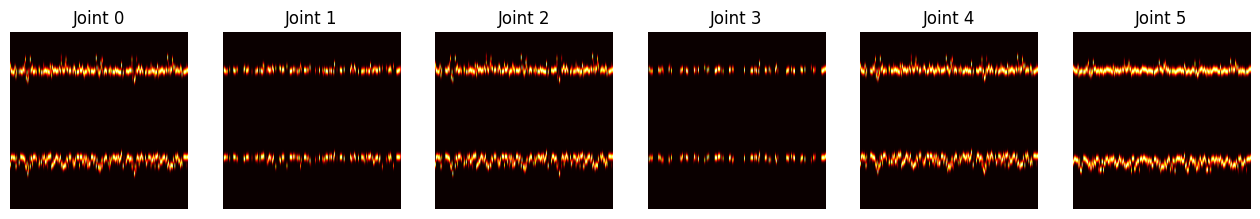

In [28]:
feat, cls_idx, rep_count = next(iter(test_loader))
feat0 = feat[0].cpu().numpy()
K = feat0.shape[0]
fig, axes = plt.subplots(1, min(6,K), figsize=(16,4))
for i in range(min(6,K)):
    axes[i].imshow(feat0[i], cmap='hot')
    axes[i].set_title(f"Joint {i}")
    axes[i].axis('off')
plt.show()

In [16]:
def train_joint_epoch(model, loader, optimizer, device, lambda_count=1.0):
    model.train()
    criterion_recog = nn.CrossEntropyLoss()
    criterion_count = nn.MSELoss()

    total, correct_recog, loss_sum = 0, 0, 0.0

    for p in model.parameters():
        p.requires_grad = True

    for feat, class_idx, rep_count in tqdm(loader, desc="Training Joint"):
        feat = feat.to(device)
        labels_recog = class_idx.to(device)
        labels_count = rep_count.float().to(device)

        optimizer.zero_grad()
        logits, pred_counts = model(feat)

        loss_recog = criterion_recog(logits, labels_recog)
        loss_count = criterion_count(pred_counts, labels_count)

        loss = loss_recog + (lambda_count * loss_count)

        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * feat.size(0)
        preds = logits.argmax(1)
        correct_recog += (preds == labels_recog).sum().item()
        total += feat.size(0)

    return loss_sum / total, correct_recog / total

In [17]:
print("\n=========================================")
print("STAGE 3: JOINT FINETUNING")
print("Unfreezing all layers, Training Shared + Recog + Counting")
print("=========================================")

model.load_state_dict(torch.load("best_multitask_f_model.pth", weights_only=True))

for param in model.parameters():
    param.requires_grad = True

optimizer_stage3 = optim.RMSprop(model.parameters(), lr=1e-4, weight_decay=1e-4)

scheduler3 = optim.lr_scheduler.MultiStepLR(optimizer_stage3, milestones=[3, 6], gamma=0.5)

EPOCHS_STAGE3 = 10
best_joint_mae = float('inf')

for epoch in range(1, EPOCHS_STAGE3 + 1):
    train_loss, train_acc = train_joint_epoch(model, train_loader, optimizer_stage3, device, lambda_count=1.0)

    metrics = evaluate_model(model, test_loader, device)
    val_acc = metrics['accuracy']
    val_mae = metrics['MAE']
    val_obo = metrics['OBO']

    scheduler3.step()
    current_lr = scheduler3.get_last_lr()[0]

    print(f"Epoch {epoch}/{EPOCHS_STAGE3} [LR={current_lr:.1e}] | Train Loss: {train_loss:.4f} Acc: {train_acc:.1%} | Val Acc: {val_acc:.1%} MAE: {val_mae:.4f} OBO: {val_obo:.1%}")

    if val_mae < best_joint_mae:
        best_joint_mae = val_mae
        torch.save(model.state_dict(), "best_joint_f_model.pth")
        print(f"  >>> New Best Joint MAE! Saved.")

print("=========================================")
print(f"Stage 3 Complete.")
print(f"Final Best Joint MAE: {best_joint_mae:.4f}")


STAGE 3: JOINT FINETUNING
Unfreezing all layers, Training Shared + Recog + Counting


Evaluating: 100%|██████████| 109/109 [00:10<00:00, 10.28it/s]


Epoch 1/10 [LR=1.0e-04] | Train Loss: 0.4597 Acc: 98.7% | Val Acc: 93.8% MAE: 0.0475 OBO: 93.3%
  >>> New Best Joint MAE! Saved.


Evaluating: 100%|██████████| 109/109 [00:10<00:00, 10.07it/s]


Epoch 2/10 [LR=1.0e-04] | Train Loss: 0.3683 Acc: 99.1% | Val Acc: 94.1% MAE: 0.0512 OBO: 93.4%


...

Epoch 8/10 [LR=2.5e-05] | Train Loss: 0.1838 Acc: 99.9% | Val Acc: 94.9% MAE: 0.0338 OBO: 95.9%


Evaluating: 100%|██████████| 109/109 [00:11<00:00,  9.81it/s]


Epoch 9/10 [LR=2.5e-05] | Train Loss: 0.1815 Acc: 99.9% | Val Acc: 95.4% MAE: 0.0361 OBO: 95.9%


Evaluating: 100%|██████████| 109/109 [00:10<00:00, 10.13it/s]

Epoch 10/10 [LR=2.5e-05] | Train Loss: 0.1557 Acc: 99.9% | Val Acc: 95.0% MAE: 0.0322 OBO: 96.2%
  >>> New Best Joint MAE! Saved.
Stage 3 Complete.
Final Best Joint MAE: 0.0322


In [18]:
#this
def predict_video_yolo(video_path, final_model):
    cap = cv2.VideoCapture(video_path)
    frames = []
    while True:
        ok, frame = cap.read()
        if not ok: break
        frames.append(frame)
    cap.release()

    if len(frames)==0:
        print("Error reading video.")
        return

    Hf, Wf = frames[0].shape[:2]

    kps = extract_kps_yolo(frames)
    kps = kps[:, selected_kps]

    kps_scaled = scale_keypoints_to_size(kps, (Wf,Hf), (64,64))

    heatmaps = keypoints_to_heatmaps(kps_scaled)

    feat = heatmaps_to_Pmap(heatmaps)
    feat = feat.unsqueeze(0).to(device)

    with torch.no_grad():
        logits, rep = final_model(feat)

    action_idx = logits.argmax(1).item()
    action_name = ["bench_press","clean_and_jerk","jumping_jacks","pullup",
                   "pushup","situp","squat"][action_idx]
    reps = float(rep.item())

    print("===================================")
    print(" Predicted Action:", action_name)
    print(" Predicted Reps:  ", reps)
    print("===================================")

    return action_name, round(reps)

In [26]:
final_model = MultiTaskModel(in_ch=17, num_classes=7).to(device)
final_model.load_state_dict(torch.load("best_joint_f_model.pth", weights_only=True)) # f
final_model.eval()

TEST_DIR = os.path.join(DATA_DIR, "Test")
MY_TEST_VIDEO = os.path.join(TEST_DIR, "test2.mp4")
TEST_VIDEO = os.path.join(VIDEO_SOURCE_DIR, "1847_c6_s2.mp4")
print(f"Testing on: {os.path.basename(TEST_VIDEO)}")

predict_video_yolo(TEST_VIDEO, final_model)

Testing on: 1847_c6_s2.mp4
 Predicted Action: squat
 Predicted Reps:   6.052938461303711


('squat', 6)

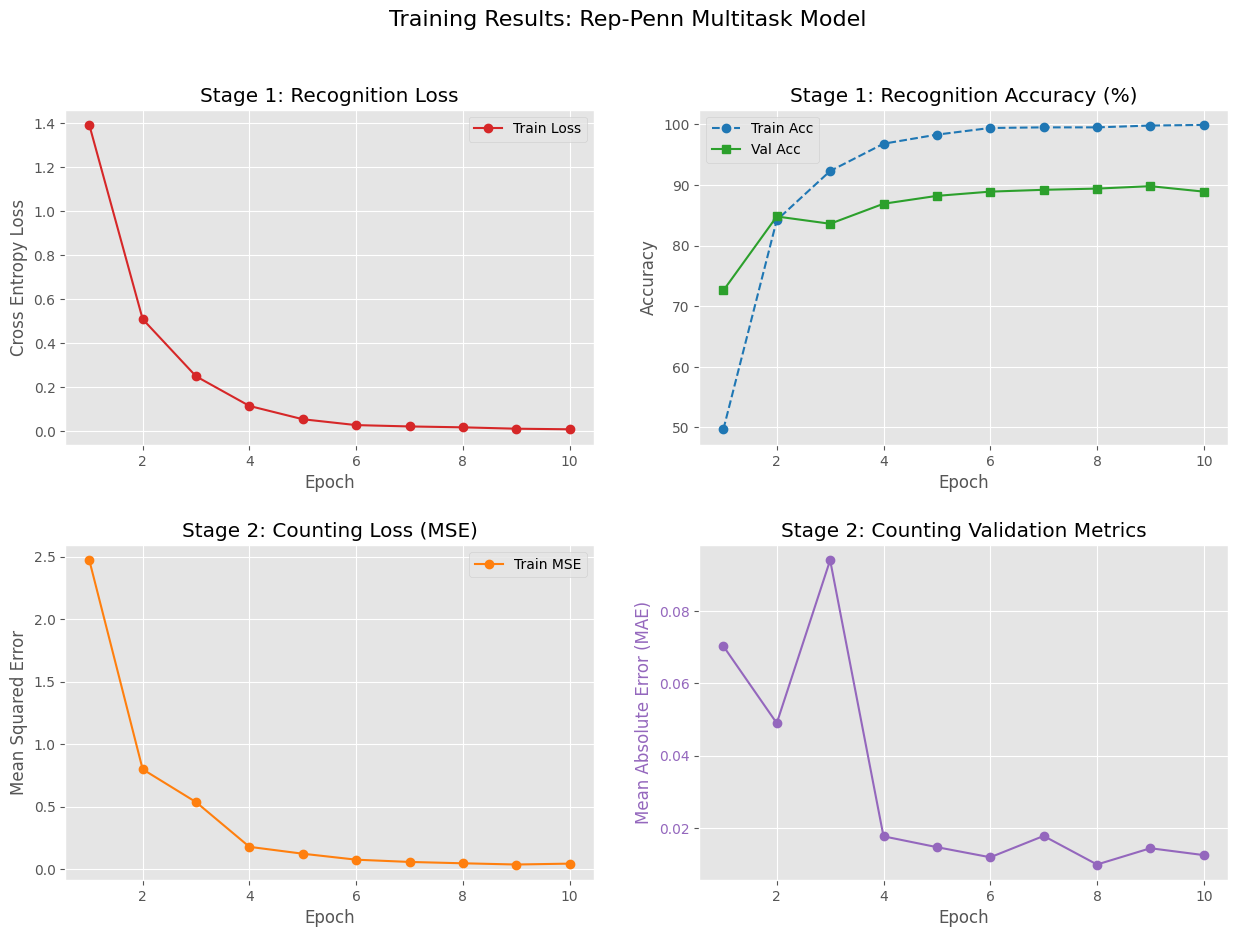

In [5]:
epochs = list(range(1, 11))

train_losses_recog = [1.3902, 0.5089, 0.2495, 0.1150, 0.0547, 0.0281, 0.0220, 0.0180, 0.0117, 0.0091]
train_acc_recog = [49.7, 84.2, 92.3, 96.8, 98.3, 99.4, 99.5, 99.5, 99.8, 99.9]
val_acc_recog = [72.6, 84.8, 83.6, 86.9, 88.2, 88.9, 89.2, 89.4, 89.8, 88.9]

train_mse_count = [2.4713, 0.7985, 0.5359, 0.1782, 0.1232, 0.0755, 0.0574, 0.0466, 0.0369, 0.0439]
val_mae_count = [0.0703, 0.0490, 0.0941, 0.0177, 0.0147, 0.0119, 0.0178, 0.0099, 0.0144, 0.0125]
val_obo_count = [85.1, 93.4, 79.9, 98.0, 98.5, 98.8, 98.9, 99.1, 99.1, 99.2]

plt.style.use('ggplot')
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
plt.subplots_adjust(hspace=0.3)

axes[0, 0].plot(epochs, train_losses_recog, marker='o', color='tab:red', label='Train Loss')
axes[0, 0].set_title('Stage 1: Recognition Loss')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Cross Entropy Loss')
axes[0, 0].legend()
axes[0, 0].grid(True)

axes[0, 1].plot(epochs, train_acc_recog, marker='o', linestyle='--', color='tab:blue', label='Train Acc')
axes[0, 1].plot(epochs, val_acc_recog, marker='s', color='tab:green', label='Val Acc')
axes[0, 1].set_title('Stage 1: Recognition Accuracy (%)')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(True)

axes[1, 0].plot(epochs, train_mse_count, marker='o', color='tab:orange', label='Train MSE')
axes[1, 0].set_title('Stage 2: Counting Loss (MSE)')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Mean Squared Error')
axes[1, 0].legend()
axes[1, 0].grid(True)

ax4 = axes[1, 1]
line1 = ax4.plot(epochs, val_mae_count, marker='o', color='tab:purple', label='Val MAE')
ax4.set_ylabel('Mean Absolute Error (MAE)', color='tab:purple')
ax4.set_xlabel('Epoch')
ax4.tick_params(axis='y', labelcolor='tab:purple')
ax4.set_title('Stage 2: Counting Validation Metrics')

plt.suptitle('Training Results: Rep-Penn Multitask Model', fontsize=16)
plt.savefig('training_plots.png', dpi=300, bbox_inches='tight')
plt.show()

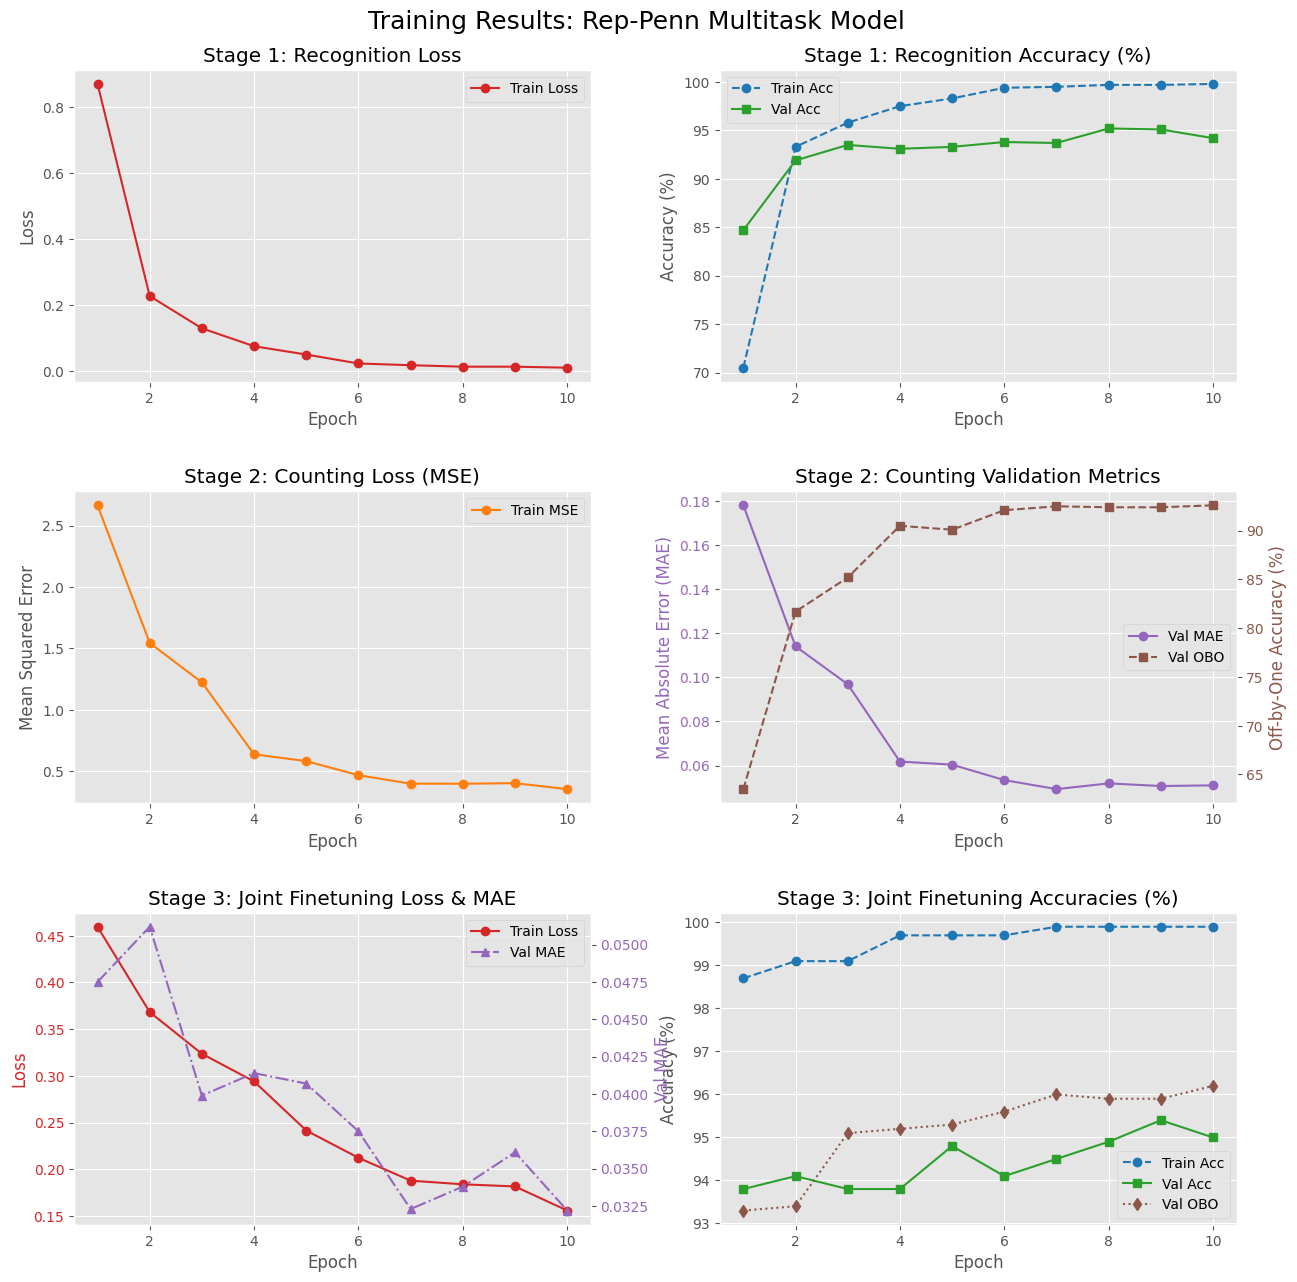

In [27]:

epochs = list(range(1, 11))

train_losses_recog = [0.8701, 0.2267, 0.1289, 0.0746, 0.0494, 0.0223, 0.0170, 0.0126, 0.0126, 0.0095]
train_acc_recog = [70.5, 93.3, 95.8, 97.5, 98.3, 99.4, 99.5, 99.7, 99.7, 99.8]
val_acc_recog = [84.7, 91.9, 93.5, 93.1, 93.3, 93.8, 93.7, 95.2, 95.1, 94.2]

train_mse_count = [2.6658, 1.5445, 1.2226, 0.6367, 0.5811, 0.4664, 0.3972, 0.3970, 0.4014, 0.3530]
val_mae_count = [0.1781, 0.1141, 0.0969, 0.0618, 0.0604, 0.0534, 0.0493, 0.0519, 0.0507, 0.0510]
val_obo_count = [63.5, 81.7, 85.2, 90.5, 90.1, 92.1, 92.5, 92.4, 92.4, 92.6]

train_joint_losses = [0.4597, 0.3683, 0.3236, 0.2940, 0.2414, 0.2122, 0.1877, 0.1838, 0.1815, 0.1557]
train_joint_acc = [98.7, 99.1, 99.1, 99.7, 99.7, 99.7, 99.9, 99.9, 99.9, 99.9]
val_joint_acc = [93.8, 94.1, 93.8, 93.8, 94.8, 94.1, 94.5, 94.9, 95.4, 95.0]
val_joint_mae = [0.0475, 0.0512, 0.0399, 0.0414, 0.0407, 0.0375, 0.0323, 0.0338, 0.0361, 0.0322]
val_joint_obo = [93.3, 93.4, 95.1, 95.2, 95.3, 95.6, 96.0, 95.9, 95.9, 96.2]


plt.style.use('ggplot')
fig, axes = plt.subplots(3, 2, figsize=(15, 15))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

axes[0, 0].plot(epochs, train_losses_recog, marker='o', color='tab:red', label='Train Loss')
axes[0, 0].set_title('Stage 1: Recognition Loss')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(True)

axes[0, 1].plot(epochs, train_acc_recog, marker='o', linestyle='--', color='tab:blue', label='Train Acc')
axes[0, 1].plot(epochs, val_acc_recog, marker='s', color='tab:green', label='Val Acc')
axes[0, 1].set_title('Stage 1: Recognition Accuracy (%)')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy (%)')
axes[0, 1].legend()
axes[0, 1].grid(True)

axes[1, 0].plot(epochs, train_mse_count, marker='o', color='tab:orange', label='Train MSE')
axes[1, 0].set_title('Stage 2: Counting Loss (MSE)')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Mean Squared Error')
axes[1, 0].legend()
axes[1, 0].grid(True)

ax4_1 = axes[1, 1]
line1 = ax4_1.plot(epochs, val_mae_count, marker='o', color='tab:purple', label='Val MAE')
ax4_1.set_ylabel('Mean Absolute Error (MAE)', color='tab:purple')
ax4_1.set_xlabel('Epoch')
ax4_1.tick_params(axis='y', labelcolor='tab:purple')
ax4_1.set_title('Stage 2: Counting Validation Metrics')

ax4_2 = ax4_1.twinx()
line2 = ax4_2.plot(epochs, val_obo_count, marker='s', linestyle='--', color='tab:brown', label='Val OBO')
ax4_2.set_ylabel('Off-by-One Accuracy (%)', color='tab:brown')
ax4_2.tick_params(axis='y', labelcolor='tab:brown')
ax4_2.grid(False)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax4_1.legend(lines, labels, loc='center right')

ax5_1 = axes[2, 0]
line3 = ax5_1.plot(epochs, train_joint_losses, marker='o', color='tab:red', label='Train Loss')
ax5_1.set_ylabel('Loss', color='tab:red')
ax5_1.set_xlabel('Epoch')
ax5_1.tick_params(axis='y', labelcolor='tab:red')
ax5_1.set_title('Stage 3: Joint Finetuning Loss & MAE')

ax5_2 = ax5_1.twinx()
line4 = ax5_2.plot(epochs, val_joint_mae, marker='^', linestyle='-.', color='tab:purple', label='Val MAE')
ax5_2.set_ylabel('Val MAE', color='tab:purple')
ax5_2.tick_params(axis='y', labelcolor='tab:purple')
ax5_2.grid(False)

lines_joint_1 = line3 + line4
labels_joint_1 = [l.get_label() for l in lines_joint_1]
ax5_1.legend(lines_joint_1, labels_joint_1, loc='upper right')

axes[2, 1].plot(epochs, train_joint_acc, marker='o', linestyle='--', color='tab:blue', label='Train Acc')
axes[2, 1].plot(epochs, val_joint_acc, marker='s', color='tab:green', label='Val Acc')
axes[2, 1].plot(epochs, val_joint_obo, marker='d', linestyle=':', color='tab:brown', label='Val OBO')
axes[2, 1].set_title('Stage 3: Joint Finetuning Accuracies (%)')
axes[2, 1].set_xlabel('Epoch')
axes[2, 1].set_ylabel('Accuracy (%)')
axes[2, 1].legend()
axes[2, 1].grid(True)

plt.suptitle('Training Results: Rep-Penn Multitask Model', fontsize=18, y=0.92)
plt.savefig('training_plots_multistage.png', dpi=300, bbox_inches='tight')
plt.show()


--- REPORT ---
                precision    recall  f1-score   support

   bench_press       0.85      0.94      0.89       208
clean_and_jerk       1.00      0.95      0.98       168
 jumping_jacks       0.99      0.96      0.98       192
        pullup       1.00      0.97      0.99       264
        pushup       0.99      0.92      0.95       368
         situp       0.91      0.95      0.93       144
         squat       0.92      0.96      0.94       392

      accuracy                           0.95      1736
     macro avg       0.95      0.95      0.95      1736
  weighted avg       0.95      0.95      0.95      1736



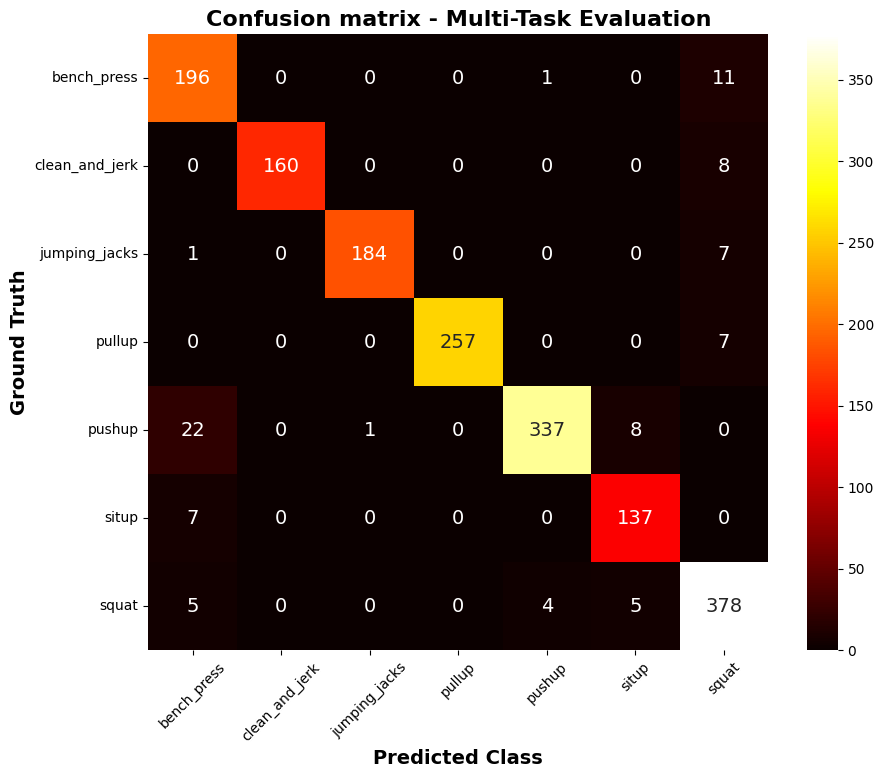

In [10]:
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

model = MultiTaskModel(in_ch=17, num_classes=7).to(device)
model.load_state_dict(torch.load("best_joint_f_model.pth", map_location=device))
model.eval()

y_true = []
y_pred = []

class_names = ['bench_press', 'clean_and_jerk', 'jumping_jacks', 'pullup', 'pushup', 'situp', 'squat']

with torch.no_grad():
    for feat, class_idx, _ in test_loader:
        feat = feat.to(device)
        labels = class_idx.long().to(device)

        logits, _ = model(feat)
        preds = logits.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

print("\n--- REPORT ---")
print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='hot',
            xticklabels=class_names, yticklabels=class_names,
            annot_kws={"size": 14})

plt.xlabel('Predicted Class', fontsize=14, fontweight='bold')
plt.ylabel('Ground Truth', fontsize=14, fontweight='bold')
plt.title('Confusion matrix - Multi-Task Evaluation', fontsize=16, fontweight='bold')
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.savefig('matrice_confuzie_rezultat.png', dpi=300, bbox_inches='tight')
plt.show()